# Klasifikasi sampah dengan MobileNetV3-Small + PCA + KNN cosine

Buka file ini di **Google Colab**, pilih runtime **CPU**, lalu klik **Runtime > Run all**. Sel pertama menyiapkan library, dataset Kaggle, pembagian data, dan bobot MobileNet. Dataset dan bobot membutuhkan sekitar 137 MB unduhan pada sesi pertama.

Notebook melatih KNN dengan `k=5` dan jarak cosine. Akurasi dihitung pada split validasi yang sama dengan eksperimen sebelumnya. Gunakan `IMAGE_PATH` untuk mencoba foto sendiri. Model diekspor di sel terakhir.

[Dataset Kaggle versi 5](https://www.kaggle.com/datasets/zlatan599/garbage-dataset-classification/versions/5) | [Bobot MobileNet ONNX](https://huggingface.co/onnxmodelzoo/mobilenet_v3_small_Opset17/tree/9bf58cd4e8303aaf25c5e90e882d752d1cb83293)

In [ ]:
# @title Persiapan otomatis
import hashlib
import io
import shutil
import subprocess
import sys
from importlib.util import find_spec
from pathlib import Path
from urllib.request import urlopen
from zipfile import ZipFile

packages = {
    "numpy": "numpy", "pandas": "pandas", "PIL": "Pillow", "scipy": "scipy",
    "onnx": "onnx>=1.17,<2", "onnxruntime": "onnxruntime>=1.20,<2",
    "sklearn": "scikit-learn",
    "joblib": "joblib", "threadpoolctl": "threadpoolctl",
}
missing = [package for module, package in packages.items() if find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "--quiet", *missing])

import joblib
import numpy as np
import onnx
import onnxruntime as ort
import pandas as pd
import sklearn
from IPython.display import display
from PIL import Image, ImageOps
from sklearn.decomposition import PCA
from sklearn.metrics import accuracy_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from threadpoolctl import threadpool_limits

root = Path.cwd()
if root.name == "notebooks":
    root = root.parent

archive_path = root / "data/raw/garbage-dataset-classification-v5.zip"
weights_path = root / "data/pretrained/mobilenet_v3_small_Opset17.onnx"
split_dir = root / "data/splits"
dataset_hash = "6860c961246ed47d3bc4a5e752757cd80a0334251e89f62997a6a6910b7a3fd7"
weights_hash = "9152343d120cf7b03b6b775a5fccd53813cc21891e376060a8edd2dfc0c35193"
revision = "9bf58cd4e8303aaf25c5e90e882d752d1cb83293"


def file_hash(path):
    digest = hashlib.sha256()
    with path.open("rb") as file:
        for chunk in iter(lambda: file.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


def download(url, path, expected_hash):
    if path.is_file():
        if file_hash(path) != expected_hash:
            raise ValueError(f"Checksum berkas berbeda: {path}")
        return
    print(f"Mengunduh {path.name} ...", flush=True)
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_suffix(".part")
    with urlopen(url, timeout=90) as response, partial.open("wb") as output:
        shutil.copyfileobj(response, output)
    if file_hash(partial) != expected_hash:
        raise ValueError(f"Unduhan {path.name} berbeda dari versi yang dipatok. Jalankan kembali sel ini.")
    partial.replace(path)


download(
    "https://www.kaggle.com/api/v1/datasets/download/zlatan599/garbage-dataset-classification?datasetVersionNumber=5",
    archive_path, dataset_hash,
)
download(
    f"https://huggingface.co/onnxmodelzoo/mobilenet_v3_small_Opset17/resolve/{revision}/{weights_path.name}",
    weights_path, weights_hash,
)


def prepare_split():
    rows = []
    with ZipFile(archive_path) as archive:
        for name in sorted(archive.namelist()):
            if not name.lower().endswith(".jpg"):
                continue
            with Image.open(io.BytesIO(archive.read(name))) as image:
                digest = hashlib.sha256(f"{image.width}x{image.height}:RGB:".encode())
                digest.update(image.convert("RGB").tobytes())
                rows.append(("data/raw/" + name, name.split("/")[-2], digest.hexdigest()))
    data = pd.DataFrame(rows, columns=["path", "class", "pixel_sha256"])
    consistent = data.groupby("pixel_sha256")["class"].transform("nunique").eq(1)
    unique = data.loc[consistent].drop_duplicates("pixel_sha256")
    train, other = train_test_split(unique, test_size=0.30, stratify=unique["class"], random_state=42)
    val, test = train_test_split(other, test_size=0.50, stratify=other["class"], random_state=42)
    split_dir.mkdir(parents=True, exist_ok=True)
    for name, frame in (("train", train), ("validation", val), ("test", test)):
        frame.sort_values("path").to_csv(split_dir / f"{name}.csv", index=False)


train_path, val_path = split_dir / "train.csv", split_dir / "validation.csv"
if not all((split_dir / f"{name}.csv").is_file() for name in ("train", "validation", "test")):
    print("Menyiapkan pembagian data tanpa gambar identik ...", flush=True)
    prepare_split()
train, val = pd.read_csv(train_path), pd.read_csv(val_path)
assert (len(train), len(val)) == (8158, 1748)
assert set(train["pixel_sha256"]).isdisjoint(val["pixel_sha256"])
print(f"Data siap · {len(train):,} latih · {len(val):,} validasi")


Data siap · 8,158 latih · 1,748 validasi


### Ekstrak fitur gambar
MobileNetV3-Small menghasilkan 576 fitur per gambar. Hasil ekstraksi disimpan di sesi ini agar bisa dipakai lagi saat notebook dijalankan ulang.


In [ ]:
preprocess = {"resize": 256, "crop": 224, "mean": (0.485, 0.456, 0.406), "std": (0.229, 0.224, 0.225)}

graph = onnx.load(weights_path)
for tensor in [*graph.graph.input, *graph.graph.output]:
    tensor.type.tensor_type.shape.dim[0].dim_param = "batch"
del graph.graph.value_info[:]
encoder = onnx.utils.Extractor(onnx.shape_inference.infer_shapes(graph)).extract_model(
    [graph.graph.input[0].name], ["/Flatten_output_0"],
)
encoder_bytes = encoder.SerializeToString()


def cpu_session(weights):
    options = ort.SessionOptions()
    options.intra_op_num_threads = 2
    options.inter_op_num_threads = 1
    return ort.InferenceSession(weights, options, providers=["CPUExecutionProvider"])


def prepare_image(image, config):
    image = ImageOps.exif_transpose(image).convert("RGB")
    width, height = image.size
    size, crop = config["resize"], config["crop"]
    image = image.resize((size * width // min(width, height), size * height // min(width, height)),
                         Image.Resampling.BILINEAR)
    left, top = round((image.width - crop) / 2), round((image.height - crop) / 2)
    pixels = np.array(image.crop((left, top, left + crop, top + crop)), dtype=np.float32) / 255
    mean, std = np.float32(config["mean"]), np.float32(config["std"])
    return ((pixels - mean) / std).transpose(2, 0, 1)


def embed(images, session, config):
    batch = np.stack([prepare_image(image, config) for image in images])
    return session.run(None, {session.get_inputs()[0].name: batch})[0]


def read_image(archive, path):
    with Image.open(io.BytesIO(archive.read(path.removeprefix("data/raw/")))) as image:
        return image.copy()


def extract(archive, paths, split):
    batches = []
    for start in range(0, len(paths), 16):
        images = [read_image(archive, path) for path in paths[start:start + 16]]
        batches.append(embed(images, session, preprocess))
        if start and start % 1600 == 0:
            print(f"{split} · {start:,}/{len(paths):,}", flush=True)
    return np.concatenate(batches)


session = cpu_session(encoder_bytes)
key = hashlib.sha256((dataset_hash + weights_hash + repr(preprocess)).encode()
                     + train_path.read_bytes() + val_path.read_bytes()).hexdigest()[:16]
cache = root / "data/processed" / f"mobilenet_v3_small_{key}.npz"
if cache.is_file():
    with np.load(cache, allow_pickle=False) as data:
        X_train, X_val = data["train"], data["validation"]
else:
    with ZipFile(archive_path) as archive:
        X_train = extract(archive, train["path"].tolist(), "Latih")
        X_val = extract(archive, val["path"].tolist(), "Validasi")
    cache.parent.mkdir(parents=True, exist_ok=True)
    partial = cache.with_suffix(".part.npz")
    np.savez(partial, train=X_train, validation=X_val)
    partial.replace(cache)

assert X_train.shape == (len(train), 576) and X_val.shape == (len(val), 576)
print(f"Fitur siap · {X_train.shape[1]} fitur per gambar")


Fitur siap · 576 fitur per gambar


### Latih model

MobileNet menghasilkan 576 fitur. StandardScaler dan PCA dipelajari dari data latih. Setelah PCA menyisakan 95% varians, setiap komponen diskalakan sebelum KNN menghitung jarak cosine.

In [ ]:
with threadpool_limits(limits=2):
    scaler = StandardScaler().fit(X_train)
    scaled = scaler.transform(X_train)
    pca = PCA(n_components=0.95, svd_solver="full").fit(scaled)
    reduced = pca.transform(scaled)
    pca_scaler = StandardScaler().fit(reduced)
    neighbors = KNeighborsClassifier(n_neighbors=5, metric="cosine", weights="distance", n_jobs=1)
    neighbors.fit(pca_scaler.transform(reduced), train["class"])

model = {
    "encoder_onnx": encoder_bytes, "preprocess": preprocess,
    "scaler": scaler, "pca": pca, "pca_scaler": pca_scaler, "knn": neighbors,
    "archive_sha256": dataset_hash, "source_sha256": weights_hash,
    "feature_cache_key": key, "sklearn_version": sklearn.__version__,
    "onnxruntime_version": ort.__version__,
}
print(f"Model siap | {pca.n_components_} komponen PCA | k={neighbors.n_neighbors} | jarak {neighbors.metric}")

Model siap | 279 komponen PCA | k=5 | jarak cosine


### Lihat hasil validasi

In [ ]:
def predict_features(features, model):
    scaled = model["scaler"].transform(features)
    reduced = model["pca"].transform(scaled)
    scaled_pca = model["pca_scaler"].transform(reduced)
    return model["knn"].predict(scaled_pca)


with threadpool_limits(limits=2):
    predictions = predict_features(X_val, model)

truth = val["class"].to_numpy()
correct = int(np.count_nonzero(predictions == truth))
accuracy = accuracy_score(truth, predictions)
macro_f1 = f1_score(truth, predictions, average="macro")
print(f"Akurasi validasi: {accuracy:.2%} ({correct:,}/{len(truth):,} gambar)")
print(f"Macro-F1 validasi: {macro_f1:.4f}")

Akurasi validasi: 89.53% (1,565/1,748 gambar)
Macro-F1 validasi: 0.8898


### Coba prediksi foto
Isi `IMAGE_PATH` untuk mencoba fotomu. Jika kosong, notebook memakai satu foto validasi.


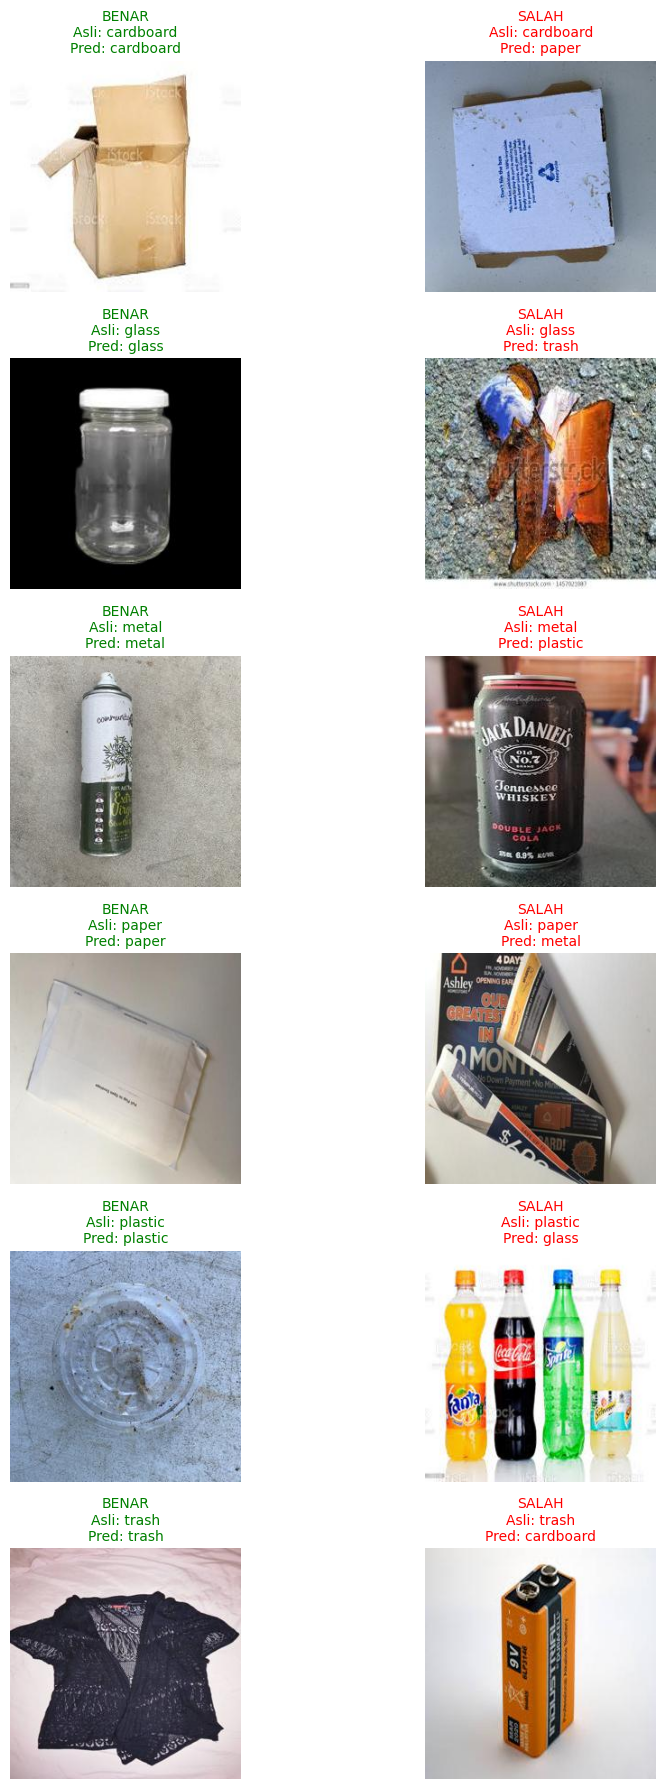

In [ ]:
# HASIL DARI GEMINI KODENYA BARU AKU UBAH BIAR JELAS

import matplotlib.pyplot as plt
IMAGE_PATH = None


def predict_photo(photo, session, model):
    features = embed([photo], session, model["preprocess"])
    return predict_features(features, model)[0]


if IMAGE_PATH is None:
    # Menyiapkan visualisasi berdampingan (Kolom 1: Benar, Kolom 2: Salah)
    classes = sorted(val["class"].unique())

    # Cari indeks prediksi benar dan salah
    correct_mask = predictions == truth
    incorrect_mask = predictions != truth

    fig, axes = plt.subplots(len(classes), 2, figsize=(10, 3 * len(classes)))

    with ZipFile(archive_path) as archive:
        for i, cls in enumerate(classes):
            # --- KOLOM 1: PREDIKSI BENAR ---
            cls_correct_indices = np.where(correct_mask & (truth == cls))[0]
            if len(cls_correct_indices) > 0:
                idx = np.random.choice(cls_correct_indices)
                sample = val.iloc[idx]
                photo = read_image(archive, sample["path"])

                axes[i, 0].imshow(ImageOps.exif_transpose(photo))
                axes[i, 0].set_title(f"BENAR\nAsli: {cls}\nPred: {predictions[idx]}", color="green", fontsize=10)
            else:
                axes[i, 0].text(0.5, 0.5, "Tidak ditemukan", ha='center', va='center')
            axes[i, 0].axis("off")

            # --- KOLOM 2: PREDIKSI SALAH ---
            cls_incorrect_indices = np.where(incorrect_mask & (truth == cls))[0]
            if len(cls_incorrect_indices) > 0:
                idx = np.random.choice(cls_incorrect_indices)
                sample = val.iloc[idx]
                photo = read_image(archive, sample["path"])

                axes[i, 1].imshow(ImageOps.exif_transpose(photo))
                axes[i, 1].set_title(f"SALAH\nAsli: {cls}\nPred: {predictions[idx]}", color="red", fontsize=10)
            else:
                axes[i, 1].text(0.5, 0.5, "Tidak ada salah\nprediksi", ha='center', va='center')
            axes[i, 1].axis("off")

    plt.tight_layout()
    plt.show()
else:
    with Image.open(IMAGE_PATH) as image:
        photo = image.copy()
    display(ImageOps.contain(ImageOps.exif_transpose(photo), (192, 192)))
    with threadpool_limits(limits=2):
        label = predict_photo(photo, session, model)
    print(f"Prediksi: {label}")


### Simpan model
Unduh `model.joblib` dari panel **Files** di Colab kalau ingin menyimpan model setelah sesi selesai.


In [ ]:
model["validation"] = {
    "images": len(truth), "correct": correct, "accuracy": accuracy, "macro_f1": macro_f1,
}
path = root / "artifacts/mobilenet_pca_knn_cosine/model.joblib"
path.parent.mkdir(parents=True, exist_ok=True)
partial = path.with_suffix(".joblib.tmp")
joblib.dump(model, partial, compress=3)

saved = joblib.load(partial)
saved_session = cpu_session(saved["encoder_onnx"])
with threadpool_limits(limits=2):
    assert predict_photo(photo, saved_session, saved) == label

partial.replace(path)
print(f"Model tersimpan: {path.relative_to(root)}")

AssertionError: 

Silakan unggah gambar Anda sendiri untuk diuji oleh model:


Saving Screenshot 2026-11-23 225108.jpg to Screenshot 2026-11-23 225108.jpg

Memproses gambar: Screenshot 2026-11-23 225108.jpg


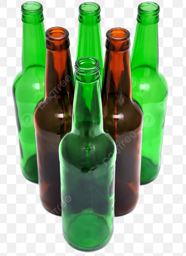

Hasil Prediksi Model: glass



In [30]:
from google.colab import files
import io
from PIL import Image, ImageOps
from threadpoolctl import threadpool_limits

print("Silakan unggah gambar Anda sendiri untuk diuji oleh model:")
uploaded = files.upload()

for file_name in uploaded.keys():
    print(f"\nMemproses gambar: {file_name}")
    # Membaca gambar yang diunggah
    image_data = uploaded[file_name]
    photo = Image.open(io.BytesIO(image_data))

    # Menampilkan gambar
    display(ImageOps.contain(ImageOps.exif_transpose(photo), (256, 256)))

    # Prediksi menggunakan model yang sudah dilatih
    with threadpool_limits(limits=2):
        features = embed([photo], session, model["preprocess"])
        pred_label = predict_features(features, model)[0]

    print(f"Hasil Prediksi Model: {pred_label}\n")
    print("=" * 40)
